## Problem Statement

Develop a Machine Learning model that predicts the selling price of vehicles using historical vehicle sales transaction data. The model should analyze various factors such as vehicle specifications, condition, mileage, market value, and transaction details to estimate the expected selling price accurately.

## Objective

The primary objective of this project is to:

- Build a predictive model capable of estimating vehicle selling prices.
- Identify the most influential factors affecting vehicle prices.
- Improve pricing strategies for dealerships and automotive businesses.
- Support market trend analysis and decision-making.

## Business Requirement

Automotive dealerships, vehicle auction platforms, banks, and insurance companies face challenges in determining accurate resale prices for vehicles due to changing market trends, vehicle conditions, mileage variations, and customer demand.

Current manual valuation methods are:

- Time-consuming
- Inconsistent
- Error-prone
- Dependent on human expertise

The organization requires an intelligent machine learning solution capable of predicting vehicle selling prices accurately using historical transaction and vehicle data.


The proposed ML solution should:

- Predict vehicle selling prices with high accuracy.
- Reduce pricing errors.
- Assist in inventory valuation.
- Enable data-driven business decisions.

In [ ]:
!pip install feature-engine

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 243.5/243.5 kB 4.5 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from feature_engine.outliers import Winsorizer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import LabelEncoder

In [ ]:
df = pd.read_csv("/content/car_prices.csv")

In [ ]:
df.head()

,year,make,model,trim,body,transmission,vin,state,condition,odometer,color,interior,seller,mmr,sellingprice,saledate
0,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg566472,ca,5.0,16639.0,white,black,kia motors america inc,20500.0,21500.0,Tue Dec 16 2014 12:30:00 GMT-0800 (PST)
1,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg561319,ca,5.0,9393.0,white,beige,kia motors america inc,20800.0,21500.0,Tue Dec 16 2014 12:30:00 GMT-0800 (PST)
2,2014,BMW,3 Series,328i SULEV,Sedan,automatic,wba3c1c51ek116351,ca,45.0,1331.0,gray,black,financial services remarketing (lease),31900.0,30000.0,Thu Jan 15 2015 04:30:00 GMT-0800 (PST)
3,2015,Volvo,S60,T5,Sedan,automatic,yv1612tb4f1310987,ca,41.0,14282.0,white,black,volvo na rep/world omni,27500.0,27750.0,Thu Jan 29 2015 04:30:00 GMT-0800 (PST)
4,2014,BMW,6 Series Gran Coupe,650i,Sedan,automatic,wba6b2c57ed129731,ca,43.0,2641.0,gray,black,financial services remarketing (lease),66000.0,67000.0,Thu Dec 18 2014 12:30:00 GMT-0800 (PST)


In [ ]:
df.shape

(338936, 16)

In [ ]:
df = df.drop(["vin", "saledate", "state"], axis=1)

In [ ]:
df.shape

(338936, 13)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 338936 entries, 0 to 338935
Data columns (total 13 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   year          338936 non-null  int64  
 1   make          333288 non-null  object 
 2   model         333227 non-null  object 
 3   trim          332959 non-null  object 
 4   body          330415 non-null  object 
 5   transmission  301718 non-null  object 
 6   condition     327143 non-null  float64
 7   odometer      338852 non-null  float64
 8   color         338437 non-null  object 
 9   interior      338437 non-null  object 
 10  seller        338936 non-null  object 
 11  mmr           338934 non-null  float64
 12  sellingprice  338934 non-null  float64
dtypes: float64(4), int64(1), object(8)
memory usage: 33.6+ MB


In [ ]:
df.isnull().sum()

,0
year,0
make,5648
model,5709
trim,5977
body,8521
transmission,37218
condition,11793
odometer,84
color,499
interior,499


In [ ]:
df.isnull().sum()/len(df)*100

,0
year,0.000000
make,1.666391
model,1.684389
trim,1.763460
body,2.514044
transmission,10.980834
condition,3.479418
odometer,0.024783
color,0.147225
interior,0.147225


In [ ]:
df.describe()

,year,condition,odometer,mmr,sellingprice
count,338936.000000,327143.000000,338852.000000,338934.000000,338934.000000
mean,2009.798776,30.333518,70370.628103,13332.595358,13157.796506
std,4.054398,13.663551,54658.727951,9418.857384,9496.028787
min,1982.000000,1.000000,1.000000,25.000000,1.000000
25%,2007.000000,23.000000,28647.000000,6550.000000,6300.000000
50%,2011.000000,34.000000,54603.500000,12000.000000,11800.000000
75%,2013.000000,41.000000,102713.500000,17850.000000,17800.000000
max,2015.000000,49.000000,999999.000000,176000.000000,169500.000000


In [ ]:
df["sellingprice"].median()

11800.0

In [ ]:
df.describe(include="object")

,make,model,trim,body,transmission,color,interior,seller
count,333288,333227,332959,330415,301718,338437,338437,338936
unique,95,939,1861,46,2,20,17,11183
top,Ford,Altima,Base,Sedan,automatic,black,black,ford motor credit company llc
freq,56845,11904,34294,146249,290965,66926,143948,11716


In [ ]:
a = df.describe()

a.columns

Index(['year', 'condition', 'odometer', 'mmr', 'sellingprice'], dtype='object')

In [ ]:
b = df.describe(include="object")

b.columns

Index(['make', 'model', 'trim', 'body', 'transmission', 'color', 'interior',
       'seller'],
      dtype='object')

In [ ]:
df.isnull().sum()

,0
year,0
make,5648
model,5709
trim,5977
body,8521
transmission,37218
condition,11793
odometer,84
color,499
interior,499


In [ ]:
df["make"] = df["make"].fillna("Ford")
df["model"] = df["model"].fillna("Altima")
df["trim"] = df["trim"].fillna("Base")
df["body"] = df["body"].fillna("Sedan")
df["transmission"] = df["transmission"].fillna("automatic")
df["color"] = df["color"].fillna("black")
df["interior"] = df["interior"].fillna("black")
df["condition"] = df["condition"].fillna(35.0)
df["odometer"] = df["odometer"].fillna(68320.0)
df["mmr"] = df["mmr"].fillna(13769.3)
df["sellingprice"] = df["sellingprice"].fillna(13611.3)

In [ ]:
df.isnull().sum()

,0
year,0
make,0
model,0
trim,0
body,0
transmission,0
condition,0
odometer,0
color,0
interior,0


In [ ]:
df.duplicated().value_counts()

,count
False,338936


<Axes: xlabel='sellingprice', ylabel='Count'>

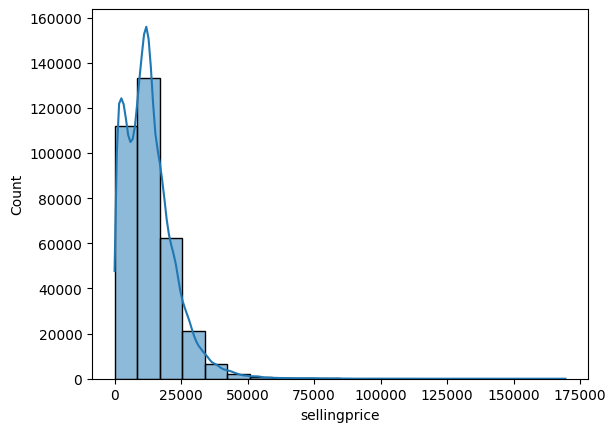

In [ ]:
sns.histplot(x="sellingprice", data=df, kde=True, bins=20)

In [ ]:
df["sellingprice"].skew()

np.float64(1.8209864939272105)

<Axes: xlabel='sellingprice'>

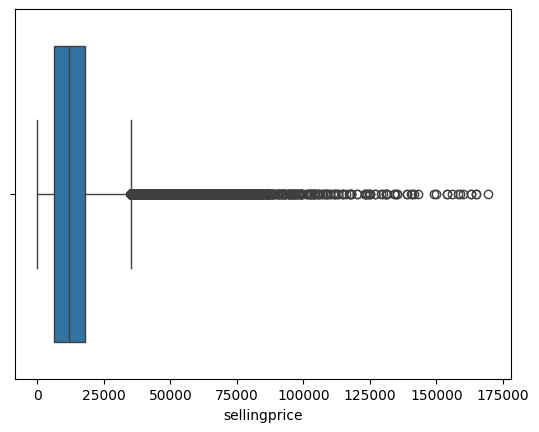

In [ ]:
sns.boxplot(x="sellingprice", data=df)

<Axes: xlabel='sellingprice', ylabel='Count'>

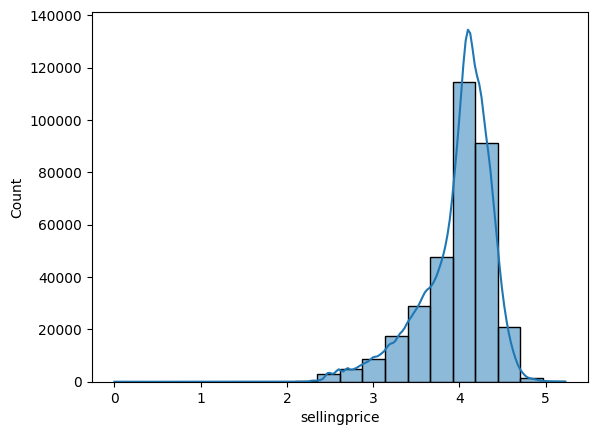

In [ ]:
sns.histplot(np.log10(df["sellingprice"]), kde=True, bins =20, fill = True)

<Axes: xlabel='condition', ylabel='Count'>

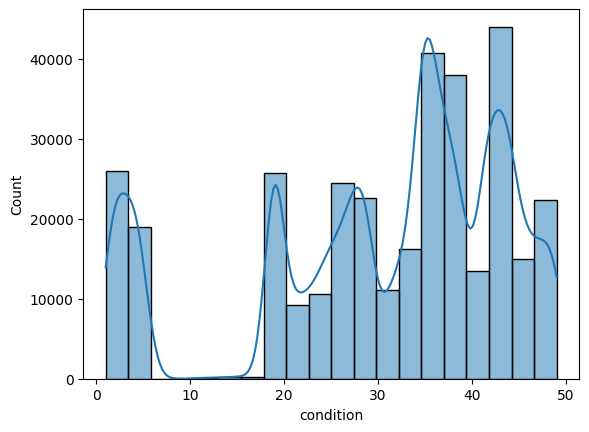

In [ ]:
sns.histplot(x="condition", data=df, kde=True, bins=20)

<Axes: xlabel='condition'>

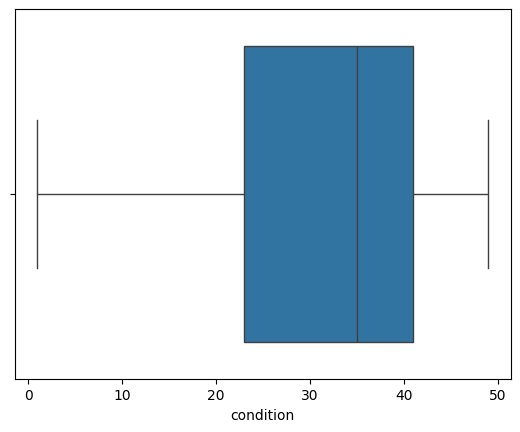

In [ ]:
sns.boxplot(x="condition", data=df)

In [ ]:
df["condition"].skew()

np.float64(-0.8412843772491069)

<Axes: xlabel='odometer', ylabel='Count'>

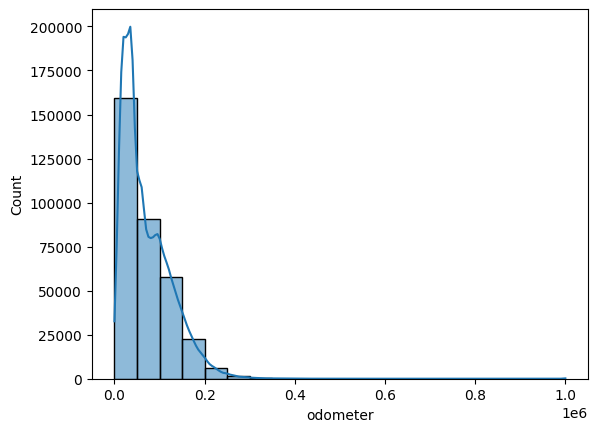

In [ ]:
sns.histplot(x="odometer", data=df, kde=True, bins=20)

<Axes: xlabel='odometer'>

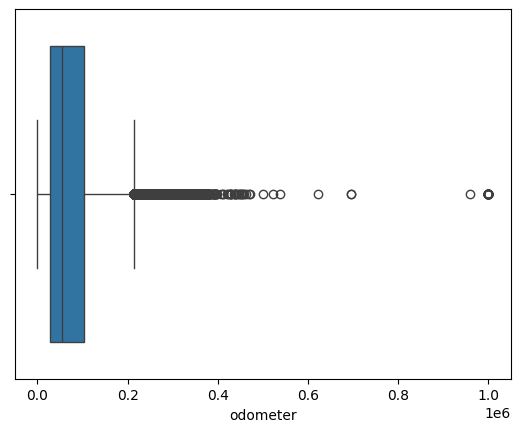

In [ ]:
sns.boxplot(x="odometer", data=df)

<Axes: xlabel='mmr', ylabel='Count'>

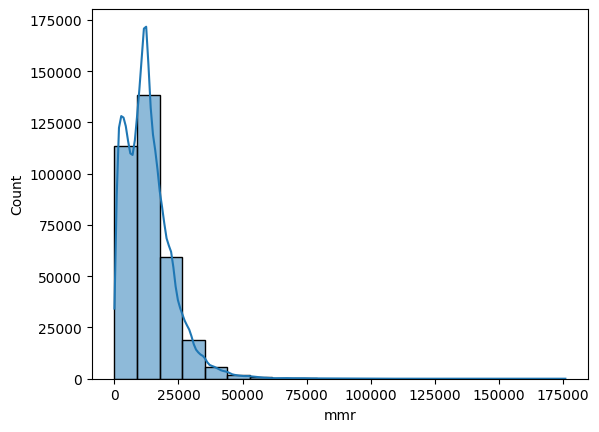

In [ ]:
sns.histplot(x="mmr", data=df, kde=True, bins=20)

<Axes: xlabel='mmr'>

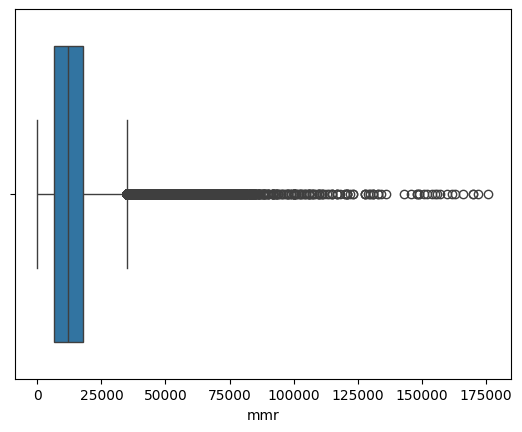

In [ ]:
sns.boxplot(x="mmr", data=df)

In [ ]:
df["sellingprice"] = np.log10(df["sellingprice"])
df["odometer"] = np.log10(df["odometer"])
df["mmr"] = np.log10(df["mmr"])

<Axes: xlabel='sellingprice'>

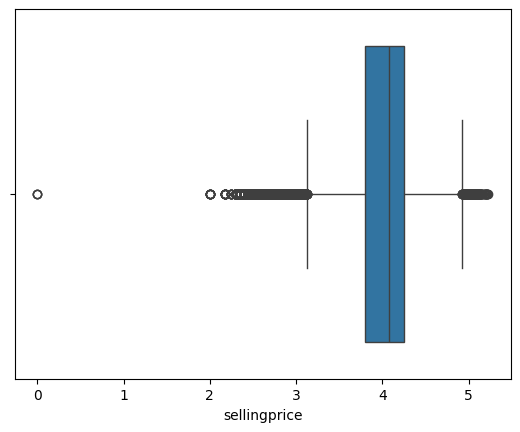

In [ ]:
sns.boxplot(x="sellingprice", data=df)

In [ ]:
df["sellingprice"].skew()

np.float64(-1.1821213288690497)

In [ ]:
df.duplicated().value_counts()

,count
False,338936


In [ ]:
le = LabelEncoder()

In [ ]:
df["make"] = le.fit_transform(df["make"])
df["model"] = le.fit_transform(df["model"])
df["trim"] = le.fit_transform(df["trim"])
df["body"] = le.fit_transform(df["body"])
df["transmission"] = le.fit_transform(df["transmission"])
df["color"] = le.fit_transform(df["color"])
df["interior"] = le.fit_transform(df["interior"])
df["seller"] = le.fit_transform(df["seller"])

In [ ]:
df.head()

,year,make,model,trim,body,transmission,condition,odometer,color,interior,seller,mmr,sellingprice
0,2015,24,631,939,35,0,5.0,4.221127,17,1,5651,4.311754,4.332438
1,2015,24,631,939,35,0,5.0,3.972804,17,0,5651,4.318063,4.332438
2,2014,3,9,265,36,0,45.0,3.124178,7,1,3905,4.503791,4.477121
3,2015,50,571,1316,36,0,41.0,4.154789,17,1,10807,4.439333,4.443263
4,2014,3,38,473,36,0,43.0,3.421768,7,1,3905,4.819544,4.826075


In [ ]:
X = df.drop(['sellingprice'], axis=1)
y = df["sellingprice"]

In [ ]:
X.head()

,year,make,model,trim,body,transmission,condition,odometer,color,interior,seller,mmr
0,2015,24,631,939,35,0,5.0,4.221127,17,1,5651,4.311754
1,2015,24,631,939,35,0,5.0,3.972804,17,0,5651,4.318063
2,2014,3,9,265,36,0,45.0,3.124178,7,1,3905,4.503791
3,2015,50,571,1316,36,0,41.0,4.154789,17,1,10807,4.439333
4,2014,3,38,473,36,0,43.0,3.421768,7,1,3905,4.819544


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=23)

In [ ]:
X_train.shape

(237255, 12)

In [ ]:
scaler = StandardScaler()

In [ ]:
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
X_train

array([[ 0.29684368,  1.88967719,  0.11412472, ..., -0.72144997,
         1.64335788,  0.2128483 ],
       [ 0.79015885, -0.52301726,  0.57603221, ..., -0.72144997,
         0.94830931,  0.93922517],
       [-1.18310183, -0.24728075,  0.63730566, ...,  2.0210567 ,
        -1.5849516 , -0.33731636],
       ...,
       [ 0.54350126,  0.92459941, -1.26688444, ..., -0.72144997,
         0.54124524,  0.33913422],
       [ 1.03681643, -0.52301726, -0.40905623, ...,  2.0210567 ,
        -1.5476609 ,  1.34277494],
       [-0.44312907, -0.24728075,  0.71271913, ...,  0.42126115,
         0.24887359,  0.10801178]])

In [ ]:
lin_reg = LinearRegression()

In [ ]:
lin_reg.fit(X_train, y_train)

LinearRegression()

In [ ]:
y_pred = lin_reg.predict(X_test)

In [ ]:
y_pred

array([4.07156976, 4.10287109, 4.21201198, ..., 3.19185706, 4.07918559,
       3.80588602])

In [ ]:
y_test

,sellingprice
38277,4.008600
207517,4.064458
230224,4.235528
174003,2.477121
142637,4.021189
...,...
336525,4.037426
80375,4.225309
81261,2.477121
62494,4.079181


In [ ]:
mean_squared_error(y_pred, y_test)

0.012046379914561244

In [ ]:
lin_reg.score(X_test, y_test)

0.9280375989724357

In [ ]:
from sklearn.metrics import r2_score

r2_score(y_test, y_pred)

0.9280375989724357

In [ ]:
scores = cross_val_score(lin_reg, X_train, y_train, cv = 5, scoring = 'r2')

print(scores)

[0.92659064 0.92909429 0.92722524 0.92253456 0.92867175]


In [ ]:
scores.mean()

np.float64(0.9268232955477161)

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

parameters = {'alpha' : [1e-15, 1e-10, 1e-8, 1e-4, 1e-3, 1e-2, 1, 5, 10, 20]}

ridge = Ridge()

grid_search = GridSearchCV(estimator=ridge, param_grid=parameters, scoring='r2', cv=5)
grid_search.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=Ridge(),
             param_grid={'alpha': [1e-15, 1e-10, 1e-08, 0.0001, 0.001, 0.01, 1,
                                   5, 10, 20]},
             scoring='r2')

In [ ]:
grid_search.best_params_

{'alpha': 1}

In [ ]:
grid_search.best_score_

np.float64(0.9268232957634213)